# 13 — From an AI-generated model to a verified simulation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/13_verified_growth_model.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

A convincing simulation is not necessarily a correct implementation. When code has been written with AI assistance, useful verification questions are still mathematical and computational: which equations were intended, what units do variables have, which limits have known answers and how does numerical error change when resolution improves?

This notebook builds small independent references for a reaction–diffusion growth model. It checks exact logistic growth, no-flux conservation, positivity, blocked transport, an intentionally wrong boundary treatment and refinement. A uniform oxygen/growth limit adds a coupled-model check. The separate three-dimensional implementation can be audited optionally at a pinned source version.

### Learning goals

1. Separate numerical verification from parameter calibration and biological validation.
2. Derive checks by removing terms from an equation.
3. Explain why two complementary checks can catch errors that either alone misses.
4. Record what was tested, which source version was used and what remains untested.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

**Reaction** is local growth at a location; **diffusion** redistributes density in space. **Carrying capacity** sets the density at which the logistic reaction stops increasing. These are model assumptions, not automatically measured properties of a particular tumor.

**No-flux boundary** prevents material from crossing the domain edge. With growth turned off, total cell count in a fixed-volume domain should remain constant. **Verification** tests whether code implements such mathematical requirements. **Validation** concerns whether the model adequately represents observations for an intended use.

**Refinement** reduces spatial or temporal step size to investigate numerical error. A visually similar image at two resolutions is weaker evidence than a measured error against a known or finer reference.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

The equation is $\partial_t c=\nabla\cdot(D\nabla c)+\rho c(1-c/K)$. Its terms have density per time units. With $D=0$, the solution from $c_0$ is

$$c(t)=\frac{K}{1+(K/c_0-1)e^{-\rho t}},$$

for positive $c_0$; the implementation handles the zero case separately. With $\rho=0$ and reflecting boundaries, integrating the diffusion term over the domain gives zero net boundary flux, so mass is conserved.

Cell-centered face fluxes make that cancellation explicit. The implementation composes explicit diffusion with exact logistic reaction using first-order splitting. In one dimension with constant $D$, an explicit diffusion step requires $D\Delta t/\Delta x^2\le1/2$ for the usual nonnegative stencil. The code also checks the appropriate bound for spatially varying transport.

An exact cosine diffusion solution tests spatial error. A finer numerical mixed-model reference tests temporal refinement; it is not an analytic solution. Distinguish these reference types when interpreting the error plots.

</details>


### Run in Colab or locally

**Colab:** click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells (**Runtime → Run all**). Setup obtains the shared code and numerical dependencies.

**Locally:** follow the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select the project's Python kernel in Cursor or JupyterLab. Setup locates the checkout and sets the working directory to `code/notebooks`, so `%load ../solutions/<filename>.py` works in either environment.

Use **File → Save a copy in Drive** to retain Colab notebook edits, and download generated files before the runtime ends. See the [execution guide](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/README.md#running-and-saving) for saving outputs and starting a fresh runtime.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.growth_verification import (
    logistic, diffuse, evolve, uniform_coupled, audit, production_audit,
    REFERENCE_COMMIT, REFERENCE_MODEL_SHA256,
)
out = root / '.build/growth-verification'
out.mkdir(parents=True, exist_ok=True)
results = audit()
reference_result = None
print('Independent NumPy reference; pinned 3-D commit:', REFERENCE_COMMIT)

Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
Independent NumPy reference; pinned 3-D commit: 81ecd42e6f37692a711208caa8d24361904f7e65


## 1. Specify the model and units

$$\partial_t c=\nabla\cdot(D\nabla c)+\rho c(1-c/K).$$

Use a slab uniform in the two transverse directions. Here $c$ and $K$ are cells/mm³, $D$ is mm²/day and $\rho$ is day⁻¹. Reflecting boundaries impose zero normal flux. Cell-centered face fluxes implement diffusion; exact logistic flow implements reaction. Composing them is a first-order splitting scheme.

The Fisher–KPP equation does not explicitly implement switching between migratory and proliferative phenotypes. Go-or-grow is a separate mechanistic hypothesis. Parameter choices below are illustrative.


## 2. Turn diffusion off and compare with an analytic solution

For $D=0$, each location follows a logistic ODE. Test the full numerical trajectory against its closed-form solution; smooth growth alone would not establish correctness.


Maximum absolute error: 1.0186340659856796e-10


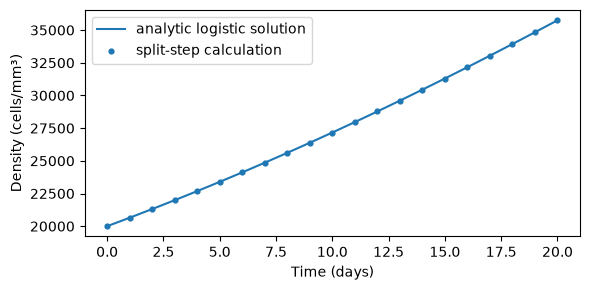

In [2]:
times = np.linspace(0, 20, 21)
initial = np.full(20, 20000.)
computed = np.array([evolve(initial, diffusion=0., duration=t)[0] for t in times])
expected = logistic(20000., .04, 100000., times)
np.testing.assert_allclose(computed, expected, rtol=1e-12)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(times, expected, label='analytic logistic solution')
ax.scatter(times, computed, s=12, label='split-step calculation')
ax.set(xlabel='Time (days)', ylabel='Density (cells/mm³)')
ax.legend(); fig.tight_layout()
fig.savefig(out / 'logistic.png', dpi=150)
print('Maximum absolute error:', np.max(np.abs(computed-expected)))

## 3. Turn proliferation off and check transport

With $\rho=0$ and zero boundary flux, integrated density (cells/mm², or cell count for a unit-area slab) must be conserved. Also check positivity and the absence of transfer across a blocked face.

Conservation alone cannot detect periodic wraparound: an incorrect periodic solver can conserve mass too. The boundary counterexample below catches that error.


In [3]:
x = (np.arange(40)+.5)*.5
start = 10000 + 2000*np.cos(np.pi*x/20)
transported = evolve(start, rho=0., diffusion=np.linspace(.05, .3, len(x)))
np.testing.assert_allclose(transported.sum()*.5, start.sum()*.5, rtol=1e-12)
assert transported.min() >= 0
edge_seed = np.array([1., 0., 0., 0.])
reflecting = diffuse(edge_seed, 1., 1., .1)
periodic_wrong_for_this_task = edge_seed + .1*(np.roll(edge_seed, 1)-2*edge_seed+np.roll(edge_seed, -1))
assert reflecting[-1] == 0 and periodic_wrong_for_this_task[-1] > 0
blocked = diffuse(edge_seed, np.array([1., 1., 0., 1.]), 1., .1)
np.testing.assert_allclose(blocked, [.9, .1, 0., 0.])
print('Reflecting edge:', reflecting)
print('Periodic counterexample:', periodic_wrong_for_this_task)
print('Relative mass error:', results['relative_mass_error'])

Reflecting edge: [0.9 0.1 0.  0. ]
Periodic counterexample: [0.8 0.1 0.  0.1]
Relative mass error: 1.4551915228366853e-16


## 4. Refine the calculation

A manufactured cosine solution supplies an independent diffusion target with reflecting boundaries. Double the spatial resolution and reduce the time step proportionally to $\Delta x^2$. For the mixed growth–diffusion calculation, compare decreasing time steps with a finer numerical reference. That reference is an approximation, not an exact solution.

These checks address numerical error under this model; they do not calibrate its biological parameters.


Spatial errors: [0.00569289 0.00142146 0.00035526]
Time-step errors: [0.11030107 0.05478848 0.02697718]
Unstable step rejected: Explicit diffusion step violates the positivity bound.


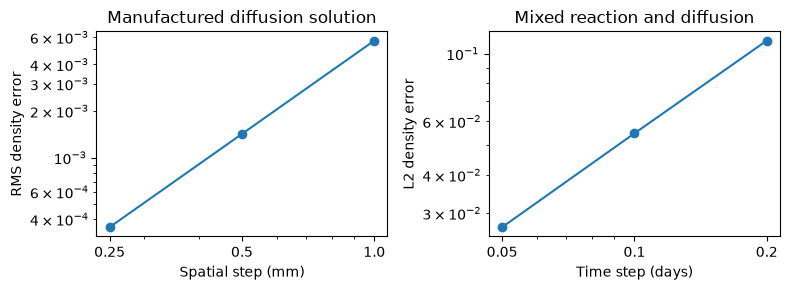

In [4]:
spatial = np.array(results['spatial_rms_errors'])
temporal = np.array(results['temporal_l2_errors'])
assert np.all(spatial[1:] < .65*spatial[:-1])
assert np.all(temporal[1:] < .65*temporal[:-1])
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].loglog([1., .5, .25], spatial, 'o-')
axes[0].set(xlabel='Spatial step (mm)', ylabel='RMS density error', title='Manufactured diffusion solution')
axes[1].loglog([.2, .1, .05], temporal, 'o-')
axes[1].set(xlabel='Time step (days)', ylabel='L2 density error', title='Mixed reaction and diffusion')
from matplotlib.ticker import NullFormatter
for ax, ticks in zip(axes, ([1., .5, .25], [.2, .1, .05])):
    ax.set_xticks(ticks, [str(t) for t in ticks])
    ax.xaxis.set_minor_formatter(NullFormatter())
fig.tight_layout(); fig.savefig(out / 'refinement.png', dpi=150)
print('Spatial errors:', spatial)
print('Time-step errors:', temporal)
try:
    diffuse(edge_seed, 1., 1., 1.)
except ValueError as exc:
    print('Unstable step rejected:', exc)
else:
    raise AssertionError('An unstable explicit step was accepted')

## 5. Check a coupled-model limiting case

The external demonstration adds viable cells $c$, necrotic material $z$ and quasi-steady oxygen $o$. For a *spatially uniform compartment*, its oxygen balance reduces to

$$o=\frac{p}{p+\beta c/K},\qquad p=\frac{1}{1+\alpha(c+z)/K}.$$

This section uses an independent uniform-compartment reference, not the oxygen PDE. With uptake $\beta=0$, initial $z=0$ and normal oxygen, the reduced calculation should recover logistic growth and produce no necrosis. With uptake restored, differences illustrate the proposed closure; they are not measured tumor physiology.


In [5]:
ordinary = float(logistic(20000., .04, 100000., 2.))
no_uptake, dead = uniform_coupled(20000., uptake=0.)
np.testing.assert_allclose(no_uptake, ordinary, rtol=1e-12)
assert dead == 0
with_uptake, dead_with_uptake = uniform_coupled(20000., uptake=4.)
print('Logistic / zero-uptake coupled:', ordinary, no_uptake)
print('Illustrative uptake case, viable / necrotic:', with_uptake, dead_with_uptake)

Logistic / zero-uptake coupled: 21310.75922435446 21310.759224354446
Illustrative uptake case, viable / necrotic: 21310.759224354446 0.0


## 6. Optional check of the pinned 3-D implementation

Set `BRAINWEB_KPP_ROOT` to a separate checkout at the commit below and use its Python environment (Numba and SciPy are needed). The [guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md#check-the-external-implementation) gives the exact commands.

The source hash is verified before import. Synthetic arrays exercise analytic reaction, diffusion conservation and the coupled Fisher–KPP limit. No BrainWeb or patient data are read. If no checkout is configured, this section explicitly reports that it was not run; independent reference checks still run above.


In [6]:
reference_checkout = os.environ.get('BRAINWEB_KPP_ROOT')
if reference_checkout:
    sys.dont_write_bytecode = True
    os.environ.setdefault('NUMBA_CACHE_DIR', str(root / '.build/numba'))
    reference_result = production_audit(reference_checkout)
    print(json.dumps(reference_result, indent=2))
else:
    print('NOT RUN: optional external 3-D implementation check.')
print('Expected model SHA-256:', REFERENCE_MODEL_SHA256)

NOT RUN: optional external 3-D implementation check.
Expected model SHA-256: 2c6da092c0b4e4eb6871094b3826485ba45b6887452094aa2bae17c6ba316e50


## 7. Record the evidence and its limits

A useful AI-assisted workflow records the proposed equations, units and assumptions, an identified implementation, independent checks, and remaining uncertainties. Passing numerical tests supports implementation correctness under tested conditions. Clinical prediction requires further parameter estimation, uncertainty analysis and withheld patient outcomes.

Try changing one boundary condition, omitting the carrying-capacity denominator, or taking an unstable step. Predict which check should fail before running it.


In [7]:
record = {
    'scope': 'independent 1-D and uniform-compartment teaching references',
    'units': {'length': 'mm', 'time': 'day', 'density': 'cells/mm^3'},
    'independent_checks': results,
    'external_commit': REFERENCE_COMMIT,
    'external_check': reference_result if reference_result is not None else 'not run',
}
(out / 'verification.json').write_text(json.dumps(record, indent=2)+'\n')
print('Saved verification record under .build/growth-verification/')
assert json.loads((out / 'verification.json').read_text()) == record


Saved verification record under .build/growth-verification/


## A verification argument needs more than one passing check

Conservation alone cannot distinguish the intended reflecting boundary from an unintended periodic boundary: both can conserve total mass. The edge-seed counterexample inspects where material can travel. A blocked face adds a second geometric constraint. Positivity catches another class of errors, while a deliberately unstable step checks that invalid numerical settings are rejected.

The logistic limit isolates the reaction implementation from transport. The spatial cosine reference and temporal refinement investigate discretization error. Decreasing errors support convergence in the tested setting; they do not establish correctness for every coefficient field, boundary geometry or duration. Record tolerances and floating-point precision when comparing implementations.

### What the coupled limit establishes

The uniform oxygen limit checks consistency of the coupled equations when spatial gradients and uptake are removed. Restoring uptake then shows how that closure changes viable and necrotic density. To test the closure biologically, identify observable oxygen and cell-density quantities and data suitable for estimating its parameters.

### Take the method beyond this example

Before accepting an AI-assisted model, write down equations, units, boundary conditions and limiting cases. Choose a reference independently of the implementation being checked. Include at least one deliberately wrong case that the checks should detect. Save a structured verification record and identify the source version. Clinical use would additionally require parameter estimation, uncertainty assessment and appropriate held-out outcomes; numerical verification supplies one part of that evidence.


## Continue from verification to interpretation and inference

The independently runnable extension follows the same two reading paths:

- [14a — Density and thresholds](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/14a_growth_density_and_thresholds.ipynb): separate tissue-dependent dynamics from the rule used to display an area.
- [14b — BrainWeb growth](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/14b_brainweb_growth.ipynb): an explicit three-dimensional normal-phantom domain and assigned growth parameters.
- [14c — Parameter recovery](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/14c_growth_parameter_recovery.ipynb): generated observations, two-parameter estimation and a later observation withheld from fitting.

The new solver is a compact independent teaching implementation. It does not replace the optional audit above or reproduce the full external oxygen/necrosis model.